In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

df = pd.read_csv(r"C:/Users/Hp/Desktop/LP3/ML/uber.csv")

print(df.head())
print(df.shape)

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [5]:
#Pre-process the dataset
df = df.drop(columns=['Unnamed: 0', 'key'], errors='ignore')

df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

df = df[
    (df['fare_amount'] > 0) &
    (df['pickup_longitude'].between(-180, 180)) &
    (df['dropoff_longitude'].between(-180, 180)) &
    (df['pickup_latitude'].between(-90, 90)) &
    (df['dropoff_latitude'].between(-90, 90)) &
    (df['passenger_count'].between(1, 6))
].copy()

# Calculate distance using Haversine formula
lat1 = np.radians(df['pickup_latitude'])
lat2 = np.radians(df['dropoff_latitude'])
lon1 = np.radians(df['pickup_longitude'])
lon2 = np.radians(df['dropoff_longitude'])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
df['distance'] = 6371 * 2 * np.arcsin(np.sqrt(a))

df = df[(df['distance'] > 0) & (df['distance'] < 100)].copy()

df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['weekday'] = df['pickup_datetime'].dt.weekday

df.drop(columns=['pickup_datetime'], inplace=True)

print("Preprocessed Dataset:", df.shape)

Preprocessed Dataset: (193191, 11)


In [6]:
#Identify and remove outliers using IQR
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['fare_amount'] < lower) | (df['fare_amount'] > upper)]

print("Number of outliers:", len(outliers))

df = df[(df['fare_amount'] >= lower) & (df['fare_amount'] <= upper)].copy()

Number of outliers: 16540


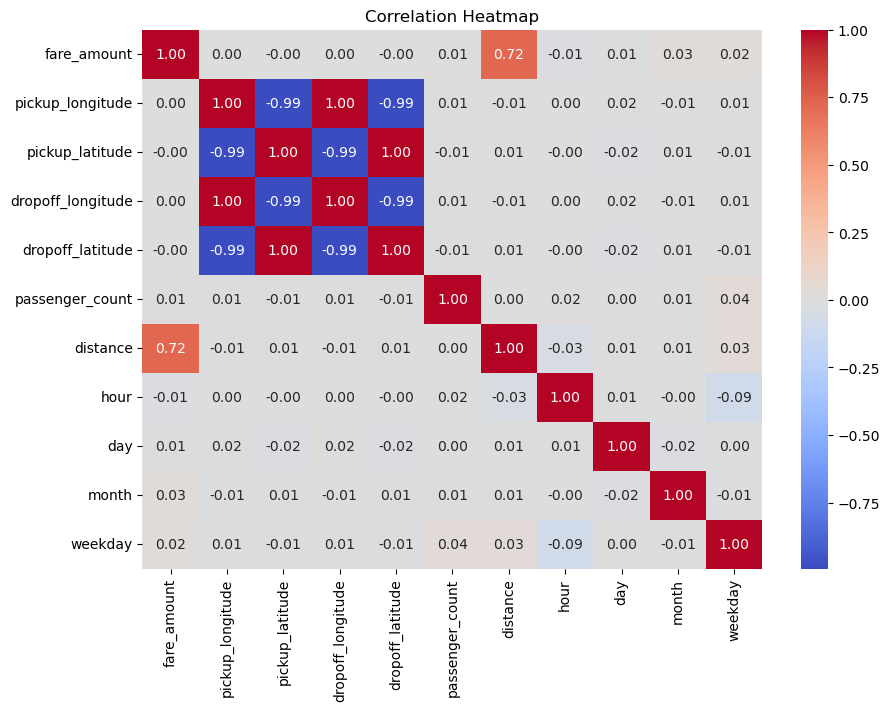

In [7]:
#Check correlation
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

In [9]:
#Split data into training and testing sets
X = df.drop('fare_amount', axis=1)
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [10]:
#Implement Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)


In [11]:
#Implement Random Forest Regression
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

In [13]:
#Evaluate and compare models
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2 Score': [
        r2_score(y_test, lr_pred),
        r2_score(y_test, rf_pred)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, lr_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred))
    ],
    'MAE': [
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, rf_pred)
    ]
})

print(results)

               Model  R2 Score      RMSE       MAE
0  Linear Regression  0.589093  2.646401  1.884474
1      Random Forest  0.741764  2.097937  1.482162


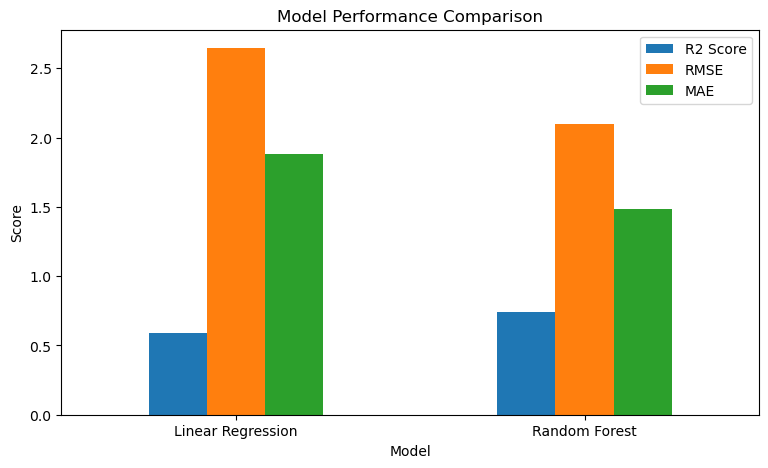

In [14]:
#Compare model performance graphically
results.set_index('Model')[['R2 Score', 'RMSE', 'MAE']].plot(
    kind='bar', figsize=(9, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.show()


In [15]:
#Predict Uber fare for a sample ride
sample = X_test.iloc[[0]]

prediction = rf.predict(sample)

print("Predicted Uber Fare: $", round(prediction[0], 2))

Predicted Uber Fare: $ 5.99


In [16]:
print(df.shape)

(176651, 11)
